# 3. Results maps

The labels from one pipeline run on the synthetic data, for H3 hexagons and for
oblasts. For an interactive version, open **`hotspots_map.jGIS`** in the file browser
(JupyterGIS): you can pan, zoom, switch layers on and off and click a cell to see its
numbers.

In [1]:
# In the browser (JupyterLite) install the packages this notebook needs.
# On a normal Python kernel this cell does nothing.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["pandas", "geopandas", "shapely", "pyproj", "matplotlib", "scipy"])

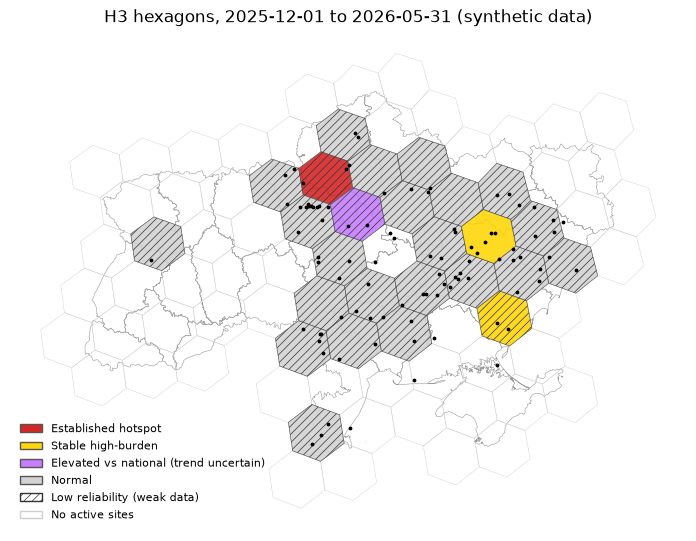

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from hotspots_lite import build_info, load_results, load_oblasts, load_sites, plot_labels, HOTSPOT_LABELS, DATA

info = build_info()
cells, oblasts, sites = load_results(), load_oblasts(), load_sites()
period = f"{info['window_start']} to {info['window_end']}"
plot_labels(cells, oblasts=oblasts, sites=sites, title=f"H3 hexagons, {period} (synthetic data)")
plt.show()

## Areas with a signal

Every area that is not *Normal*, with its data and the national reference ratio
(the area's recent share divided by the national share, median and 95 % interval).

In [3]:
cols = ["name", "oblast", "label", "reliability", "tests_curr", "recent_curr",
        "ratio_median", "ratio_lo", "ratio_hi"]
cells[cells["label"].notna() & cells["label"].ne("Normal")][cols].sort_values(
    "ratio_median", ascending=False).round(2)

,name,oblast,label,reliability,tests_curr,recent_curr,ratio_median,ratio_lo,ratio_hi
49,Hex in Drabivska,Cherkaska,Elevated vs national (trend uncertain),LOW,7.0,2.0,9.96,1.28,33.17
37,Hex in Kozeletska,Chernihivska,Established hotspot,LOW,41.0,4.0,3.91,0.76,11.66
73,Hex in Verbkivska,Dnipropetrovska,Stable high-burden,MODERATE,138.0,7.0,3.01,0.74,7.31
22,Hex in Kostiantynivska,Zaporizka,Stable high-burden,LOW,93.0,4.0,2.87,0.66,6.89


## Oblasts

The same model on oblasts. Larger areas hold more tests, so their estimates are
usually more reliable, but a signal concentrated in one city is diluted across a whole
oblast.

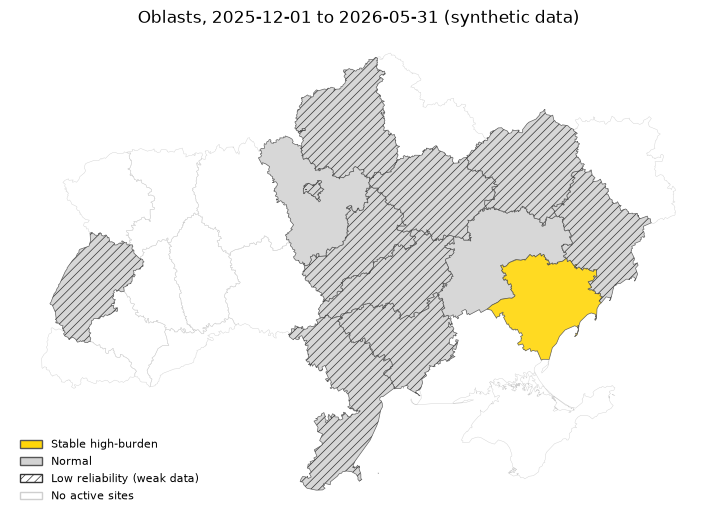

,oblast_name,label,reliability,tests_curr,recent_curr,ratio_median,ratio_lo,ratio_hi
12,Zaporizka,Stable high-burden,MODERATE,93,4,2.7,0.85,6.32


In [4]:
obl = pd.read_csv(DATA / "results_oblast.csv")
o = oblasts.merge(obl, left_on="oblast", right_on="oblast_name", how="left")
plot_labels(o, title=f"Oblasts, {period} (synthetic data)")
plt.show()
obl[obl["label"].ne("Normal")][["oblast_name", "label", "reliability", "tests_curr", "recent_curr",
                                "ratio_median", "ratio_lo", "ratio_hi"]].round(2)

## Watch-list

Some areas never pass the 0.80 rule simply because they are small, yet carry a large
share of the country's recent results or an unusually high rate. The pipeline lists
them separately as a **watch-list**: not hotspots, but places to keep an eye on.

In [5]:
w = cells[cells.get("on_watchlist", False) == True]
w[["name", "oblast", "label", "tests_curr", "recent_curr"]] if len(w) else "No cells on the watch-list in this window."

'No cells on the watch-list in this window.'